# Tanishq Ikhar
# A-A2-28
# LAB 8

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('ai4i2020.csv')

In [3]:
df.head()


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [9]:
df.tail()


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [5]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [7]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.shape


(10000, 14)

In [11]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [12]:
df.columns


Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [13]:
df.dtypes

,0
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


In [14]:
df["Type"].unique()

array(['M', 'L', 'H'], dtype=object)

In [15]:
df["Machine failure"].value_counts()

,count
Machine failure,
0,9661
1,339


In [16]:
df['Machine failure'].value_counts(normalize=True)*100

,proportion
Machine failure,
0,96.61
1,3.39


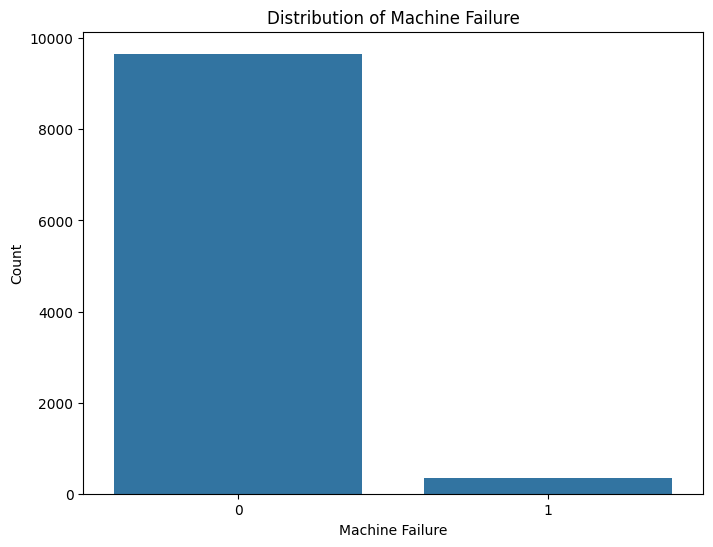

In [17]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Machine failure', data=df)
plt.title("Distribution of Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Count")
plt.show()


In [18]:
y = df["Machine failure"]

In [20]:

X = df.drop(columns=['UDI', 'Product ID', 'Machine failure'])

print("Input Shape: ", X.shape)
print("Output Shape: ", y.shape)

Input Shape:  (10000, 11)
Output Shape:  (10000,)


In [21]:
categorial_features = ['Type']
numerical_features = ['Process temperature [K]', 'Rotational speed [rpm]',
       'Torque [Nm]', 'Tool wear [min]', 'Air temperature [K]']


In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify = y)

In [24]:
print("X_train shape:", X_train.shape[0])
print("X_test shape:", X_test.shape[0])


X_train shape: 8000
X_test shape: 2000


In [25]:
preprocessor = ColumnTransformer(transformers=[("num",StandardScaler(),numerical_features),
                                               ("cat",OneHotEncoder(handle_unknown="ignore"),categorial_features)])

# **Kernel-Linear**

In [26]:
linear_svm = Pipeline(steps=[("preprocessor", preprocessor),
                             ("classifier", SVC(kernel="linear"))])
linear_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]',
                                                   'Air temperature [K]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [29]:
y_pred_linear = linear_svm.predict(X_test)

In [30]:
accuracy_linear = accuracy_score(y_test, y_pred_linear)

precision_linear = precision_score(y_test, y_pred_linear,zero_division=0)

f1_linear = f1_score(y_test, y_pred_linear,zero_division=0)

recall_linear = recall_score(y_test, y_pred_linear,zero_division=0)

print("Accuracy:", accuracy_linear)
print("Precision:", precision_linear)
print("F1 Score:", f1_linear)
print("Recall:", recall_linear)

Accuracy: 0.966
Precision: 0.0
F1 Score: 0.0
Recall: 0.0


In [32]:
print(classification_report(y_test,y_pred_linear,target_names=["No Failure", "Failure"],zero_division=0))

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



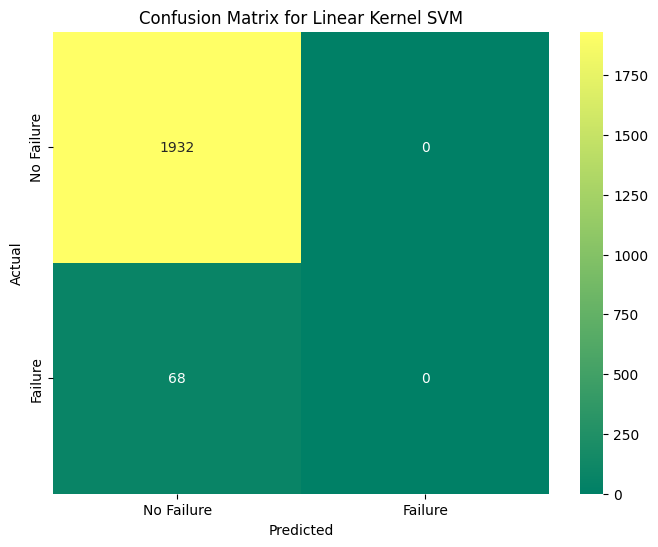

In [36]:
cm_linear = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_linear, annot=True, fmt="d", cmap="summer",
            xticklabels=["No Failure", "Failure"],
            yticklabels=["No Failure", "Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Linear Kernel SVM")

plt.show()

# **Kernel-RBF**

In [42]:
rbf_svm = Pipeline(steps=[("preprocessor", preprocessor),
                             ("classifier", SVC(kernel="rbf"))])
rbf_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]',
                                                   'Air temperature [K]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [43]:
y_pred_rbf = rbf_svm.predict(X_test)

In [44]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

precision_rbf = precision_score(y_test, y_pred_rbf, zero_division=0)

f1_rbf = f1_score(y_test, y_pred_rbf, zero_division=0)

recall_rbf = recall_score(y_test, y_pred_rbf, zero_division=0)

print("Accuracy:", accuracy_rbf)
print("Precision:", precision_rbf)
print("F1 Score:", f1_rbf)
print("Recall:", recall_rbf)

Accuracy: 0.972
Precision: 0.875
F1 Score: 0.3333333333333333
Recall: 0.20588235294117646


In [45]:
print(classification_report(
    y_test,
    y_pred_rbf,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



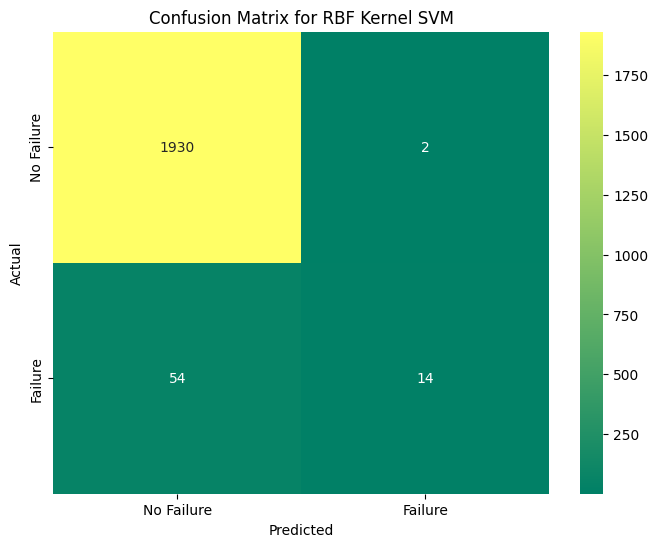

In [46]:
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_rbf, annot=True, fmt="d", cmap="summer",
            xticklabels=["No Failure", "Failure"],
            yticklabels=["No Failure", "Failure"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for RBF Kernel SVM")

plt.show()

# **Kernel-Polynomial**

Accuracy: 0.9745
Precision: 0.8695652173913043
F1 Score: 0.43956043956043955
Recall: 0.29411764705882354
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.87      0.29      0.44        68

    accuracy                           0.97      2000
   macro avg       0.92      0.65      0.71      2000
weighted avg       0.97      0.97      0.97      2000



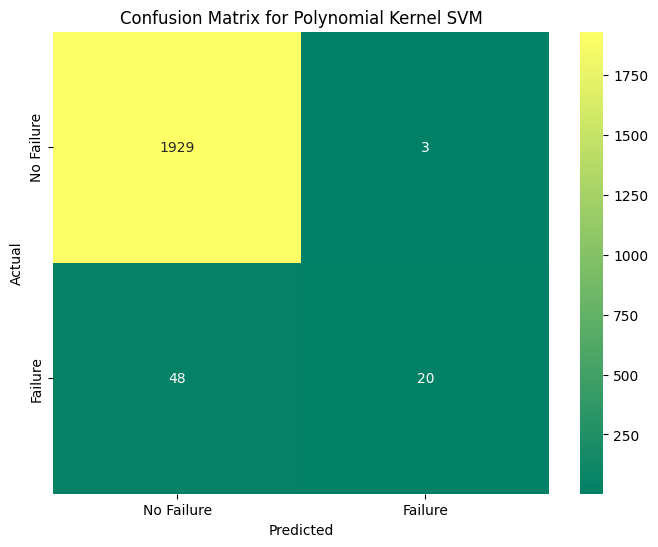

In [47]:
# Polynomial Kernel SVM
poly_svm = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="poly"))
])

poly_svm.fit(X_train, y_train)

y_pred_poly = poly_svm.predict(X_test)


# Evaluation Metrics
accuracy_poly = accuracy_score(y_test, y_pred_poly)

precision_poly = precision_score(
    y_test, y_pred_poly, zero_division=0
)

f1_poly = f1_score(
    y_test, y_pred_poly, zero_division=0
)

recall_poly = recall_score(
    y_test, y_pred_poly, zero_division=0
)

print("Accuracy:", accuracy_poly)
print("Precision:", precision_poly)
print("F1 Score:", f1_poly)
print("Recall:", recall_poly)


# Classification Report
print(classification_report(
    y_test,
    y_pred_poly,
    target_names=["No Failure", "Failure"],
    zero_division=0
))


# Confusion Matrix
cm_poly = confusion_matrix(y_test, y_pred_poly)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_poly,
    annot=True,
    fmt="d",
    cmap="summer",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Polynomial Kernel SVM")

plt.show()

# **Kernel - Sigmoid**

Accuracy: 0.945
Precision: 0.15
F1 Score: 0.140625
Recall: 0.1323529411764706
              precision    recall  f1-score   support

  No Failure       0.97      0.97      0.97      1932
     Failure       0.15      0.13      0.14        68

    accuracy                           0.94      2000
   macro avg       0.56      0.55      0.56      2000
weighted avg       0.94      0.94      0.94      2000



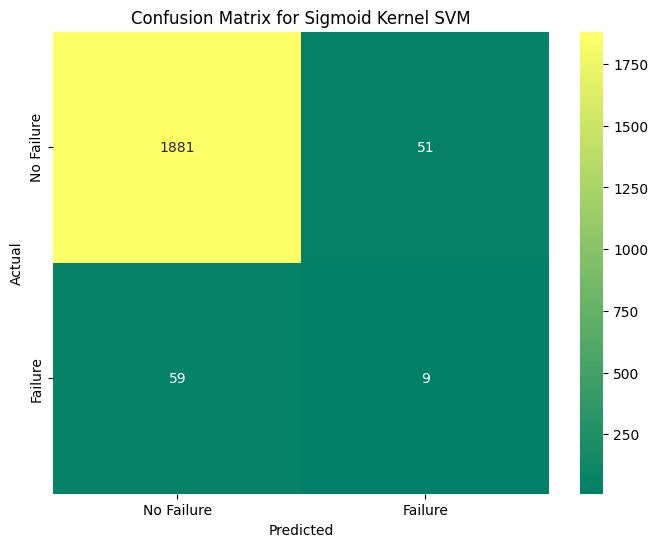

In [48]:
# Sigmoid Kernel SVM
sigmoid_svm = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="sigmoid"))
])

sigmoid_svm.fit(X_train, y_train)

y_pred_sigmoid = sigmoid_svm.predict(X_test)


# Evaluation Metrics
accuracy_sigmoid = accuracy_score(y_test, y_pred_sigmoid)

precision_sigmoid = precision_score(
    y_test, y_pred_sigmoid, zero_division=0
)

f1_sigmoid = f1_score(
    y_test, y_pred_sigmoid, zero_division=0
)

recall_sigmoid = recall_score(
    y_test, y_pred_sigmoid, zero_division=0
)

print("Accuracy:", accuracy_sigmoid)
print("Precision:", precision_sigmoid)
print("F1 Score:", f1_sigmoid)
print("Recall:", recall_sigmoid)


# Classification Report
print(classification_report(
    y_test,
    y_pred_sigmoid,
    target_names=["No Failure", "Failure"],
    zero_division=0
))


# Confusion Matrix
cm_sigmoid = confusion_matrix(y_test, y_pred_sigmoid)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_sigmoid,
    annot=True,
    fmt="d",
    cmap="summer",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Sigmoid Kernel SVM")

plt.show()

In [50]:

accuracy_linear = 0.9660
precision_linear = 0.0
f1_linear = 0.0
recall_linear = 0.0

comparison = pd.DataFrame({
    'Kernel': ['Linear', 'RBF', 'Polynomial', 'Sigmoid'],
    'Accuracy': [accuracy_linear, accuracy_rbf, accuracy_poly, accuracy_sigmoid],
    'Precision': [precision_linear, precision_rbf, precision_poly, precision_sigmoid],
    'F1 Score': [f1_linear, f1_rbf, f1_poly, f1_sigmoid],
    'Recall': [recall_linear, recall_rbf, recall_poly, recall_sigmoid]
})

comparison

,Kernel,Accuracy,Precision,F1 Score,Recall
0,Linear,0.9660,0.000000,0.000000,0.000000
1,RBF,0.9720,0.875000,0.333333,0.205882
2,Polynomial,0.9745,0.869565,0.439560,0.294118
3,Sigmoid,0.9450,0.150000,0.140625,0.132353


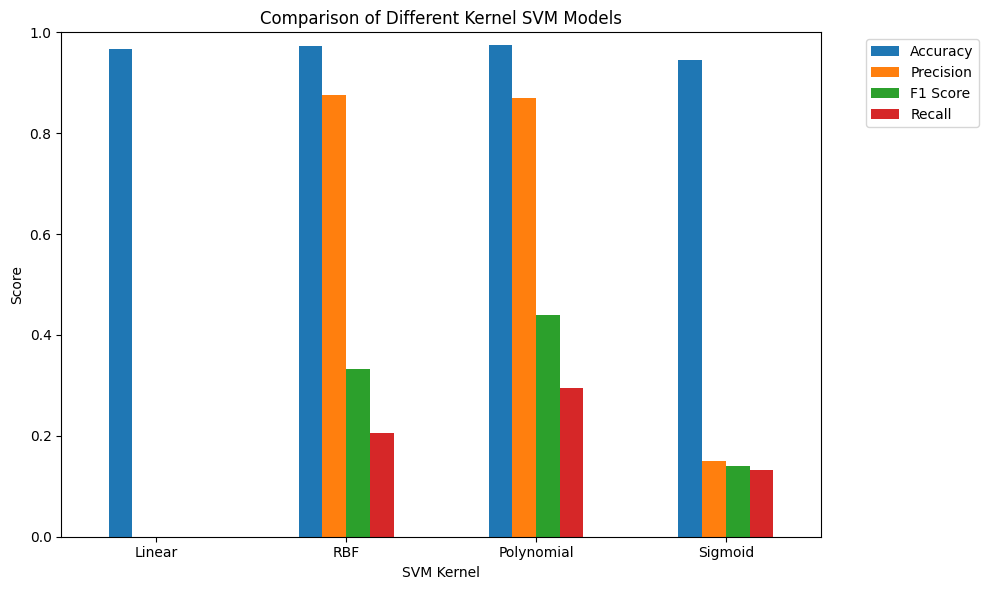

In [54]:
comparison_plot = comparison.set_index("Kernel")
comparison_plot.plot(kind="bar",figsize=(10,6))
plt.title("Comparison of Different Kernel SVM Models")
plt.xlabel("SVM Kernel")
plt.ylabel("Score")

plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05,1),loc="upper left")
plt.tight_layout()

plt.show()

In [55]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", SVC())]
)

In [58]:
param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10, 100]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.01, 0.1, 1]
    }
]

In [61]:
grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=5, scoring="f1",n_jobs=-1,verbose=1)

In [65]:

grid_search.fit(X_train, y_train)



Fitting 5 folds for each of 20 candidates, totalling 100 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['Process '
                                                                          'temperature '
                                                                          '[K]',
                                                                          'Rotational '
                                                                          'speed '
                                                                          '[rpm]',
                                                                          'Torque '
                                                                          '[Nm]',
                                                                          'Tool '
                                                                          'wear '
                                                                          '[min]',
                                                                          'Air '
                                                                          'temperature '
                                                                          '[K]']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['Type'])])),
                                       ('classifier', SVC())]),
             n_jobs=-1,
             param_grid=[{'classifier__C': [0.1, 1, 10, 100],
                          'classifier__kernel': ['linear']},
                         {'classifier__C': [0.1, 1, 10, 100],
                          'classifier__gamma': ['scale', 0.01, 0.1, 1],
                          'classifier__kernel': ['rbf']}],
             scoring='f1', verbose=1)

In [66]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}


In [67]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)


In [68]:
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)

precision_tuned = precision_score(y_test, y_pred_tuned, zero_division=0)

f1_tuned = f1_score(y_test, y_pred_tuned, zero_division=0)

recall_tuned = recall_score(y_test, y_pred_tuned, zero_division=0)

print("Tuned SVM Results")
print("-----------------")
print("Accuracy:", accuracy_tuned)
print("Precision:", precision_tuned)
print("F1 Score:", f1_tuned)
print("Recall:", recall_tuned)

Tuned SVM Results
-----------------
Accuracy: 0.98
Precision: 0.7592592592592593
F1 Score: 0.6721311475409836
Recall: 0.6029411764705882
